**load libaries**

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**load df**

In [17]:
df = pd.read_parquet("../data/combined_all.parquet")

**variables**

In [18]:
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]

**Which products drive the most revenue and sales volume, and which products may require a review of their inventory strategy?**

In [19]:
product_df = df.groupby("category").agg(
    revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index().round(2).sort_values(by="revenue",ascending=False)
product_df

,category,revenue,volume,orders
7,home decor & ornaments,2708197.38,1386333,27411
9,kitchenware & dining,2542298.70,1171941,27504
0,bags & travel accessories,2198988.92,1206380,20215
15,textiles & soft furnishings,1812764.24,472801,19066
14,storage & household organization,1808622.63,685774,24834
2,"candles, lighting & fragrance",1742598.70,1025607,23373
12,party & gift supplies,1734860.75,1881797,22680
11,other,1202923.11,466484,24096
3,christmas & seasonal decorations,1051436.59,698999,12962
17,toys & games,567023.95,438007,13326


**inventory trend analysis**

In [21]:
inventory_trends = df.groupby(["year","month","category"]).agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index().round(2)
inventory_trends["month"] = pd.Categorical(inventory_trends["month"], categories=month_order, ordered=True)
inventory_trends = inventory_trends.sort_values(by=["category","year","month"]).reset_index(drop=True)
inventory_trends["aov"] = (inventory_trends["net_revenue"] / inventory_trends["orders"]).round(2)

g = inventory_trends.groupby("category")
for col in ["net_revenue", "volume", "orders", "aov"]:
    name = "revenue" if col == "net_revenue" else col
    inventory_trends[f"{name}_growth_rate"] = (g[col].pct_change() * 100).round(2)
inventory_trends

,year,month,category,net_revenue,volume,orders,aov,revenue_growth_rate,volume_growth_rate,orders_growth_rate,aov_growth_rate
0,2009,December,bags & travel accessories,98264.27,48434,844,116.43,NaN,NaN,NaN,NaN
1,2010,January,bags & travel accessories,76527.65,40098,532,143.85,-22.12,-17.21,-36.97,23.55
2,2010,February,bags & travel accessories,62745.64,47151,658,95.36,-18.01,17.59,23.68,-33.71
3,2010,March,bags & travel accessories,79032.88,43731,914,86.47,25.96,-7.25,38.91,-9.32
4,2010,April,bags & travel accessories,79027.17,44847,809,97.69,-0.01,2.55,-11.49,12.98
...,...,...,...,...,...,...,...,...,...,...,...
470,2011,August,unknown,0.00,-2555,82,0.00,NaN,-44.24,-47.10,NaN
471,2011,September,unknown,0.00,-7149,99,0.00,NaN,179.80,20.73,NaN
472,2011,October,unknown,0.00,-365,104,0.00,NaN,-94.89,5.05,NaN
473,2011,November,unknown,0.00,907,75,0.00,NaN,-348.49,-27.88,NaN


**inventory summary**

In [28]:
inventory_summary = inventory_trends.groupby("category").agg(
    revenue = ("net_revenue","sum"),
    volume = ("volume","sum")
).reset_index().sort_values("revenue",ascending=False)
inventory_summary

,category,revenue,volume
7,home decor & ornaments,2708197.38,1386333
9,kitchenware & dining,2542298.70,1171941
0,bags & travel accessories,2198988.92,1206380
15,textiles & soft furnishings,1812764.23,472801
14,storage & household organization,1808622.63,685774
2,"candles, lighting & fragrance",1742598.70,1025607
12,party & gift supplies,1734860.75,1881797
11,other,1202923.11,466484
3,christmas & seasonal decorations,1051436.59,698999
17,toys & games,567023.95,438007


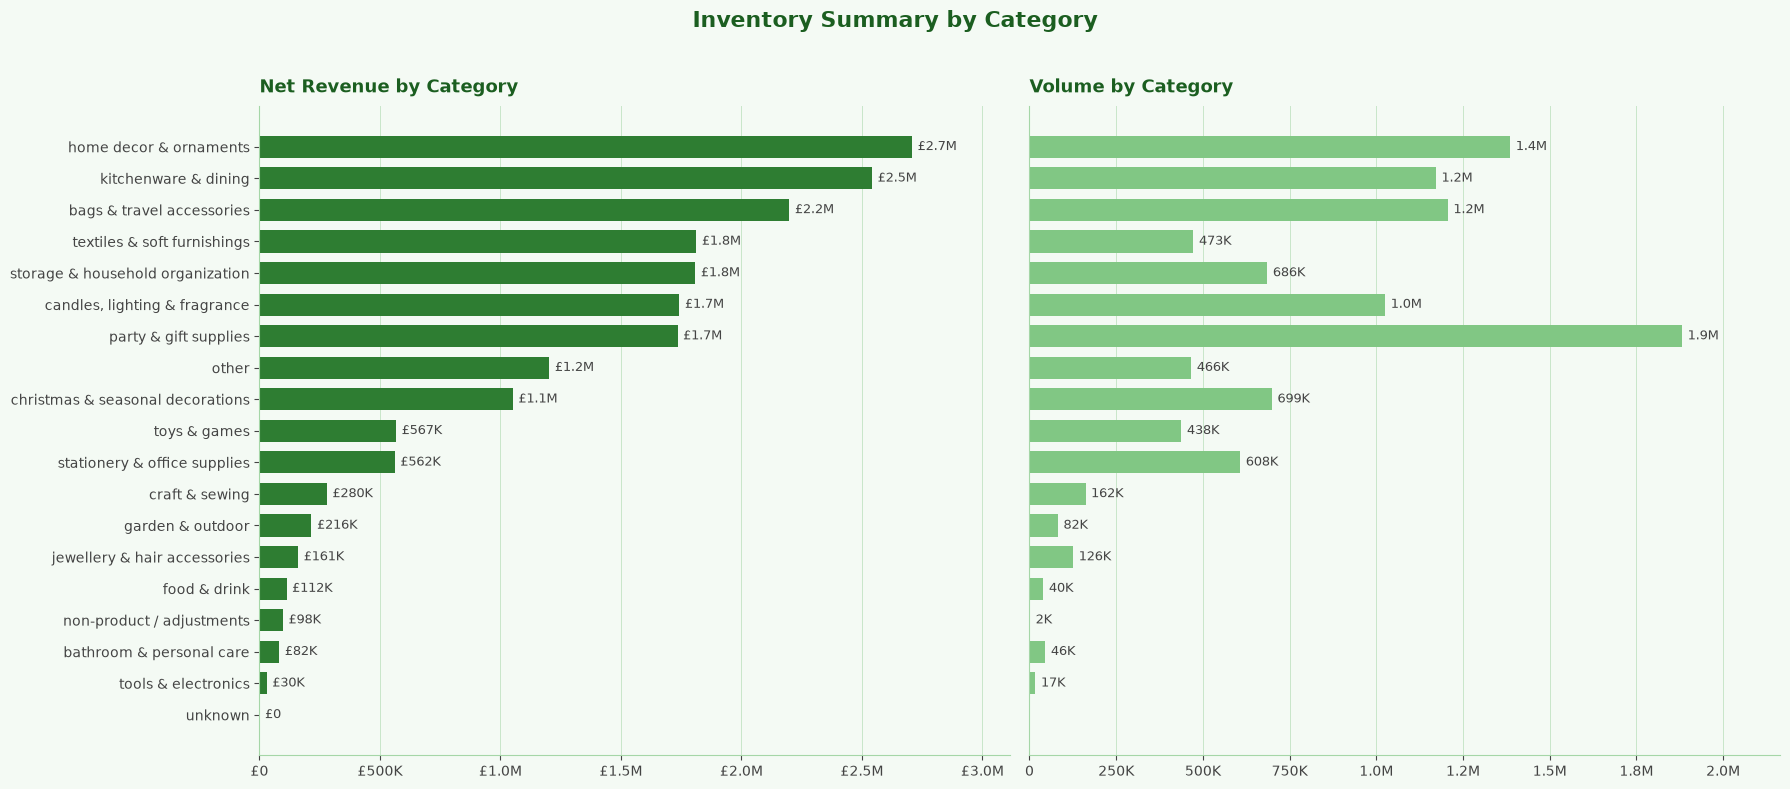

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

dark, mid, light, bg = "#1B5E20", "#2E7D32", "#81C784", "#F4FAF4"

def gbp(x, _):
    if abs(x) >= 1e6: return f"£{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"£{x/1e3:.0f}K"
    return f"£{x:,.0f}"

def num(x, _):
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"{x/1e3:.0f}K"
    return f"{x:,.0f}"

d = inventory_summary.sort_values("revenue", ascending=True)  # barh plots bottom-up

fig, (ax, bx) = plt.subplots(1, 2, figsize=(18, 8), facecolor=bg, sharey=True)

for a, col, color, title, fmt in [
    (ax, "revenue", mid, "Net Revenue by Category", gbp),
    (bx, "volume", light, "Volume by Category", num),
]:
    bars = a.barh(d["category"], d[col], color=color, height=0.7)
    a.set_title(title, fontsize=13, fontweight="bold", color=dark, loc="left", pad=10)
    a.xaxis.set_major_formatter(FuncFormatter(fmt))
    a.bar_label(bars, labels=[fmt(v, None) for v in d[col]], padding=4,
                fontsize=9, color="#444")
    a.set_xlim(0, d[col].max() * 1.15)  # room for the labels
    a.set_facecolor(bg)
    a.grid(axis="x", color="#C8E6C9", linewidth=0.7)
    a.set_axisbelow(True)
    for s in ["top", "right"]:
        a.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        a.spines[s].set_color("#A5D6A7")
    a.tick_params(colors="#444")

bx.tick_params(axis="y", left=False)

fig.suptitle("Inventory Summary by Category", fontsize=16, fontweight="bold", color=dark)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

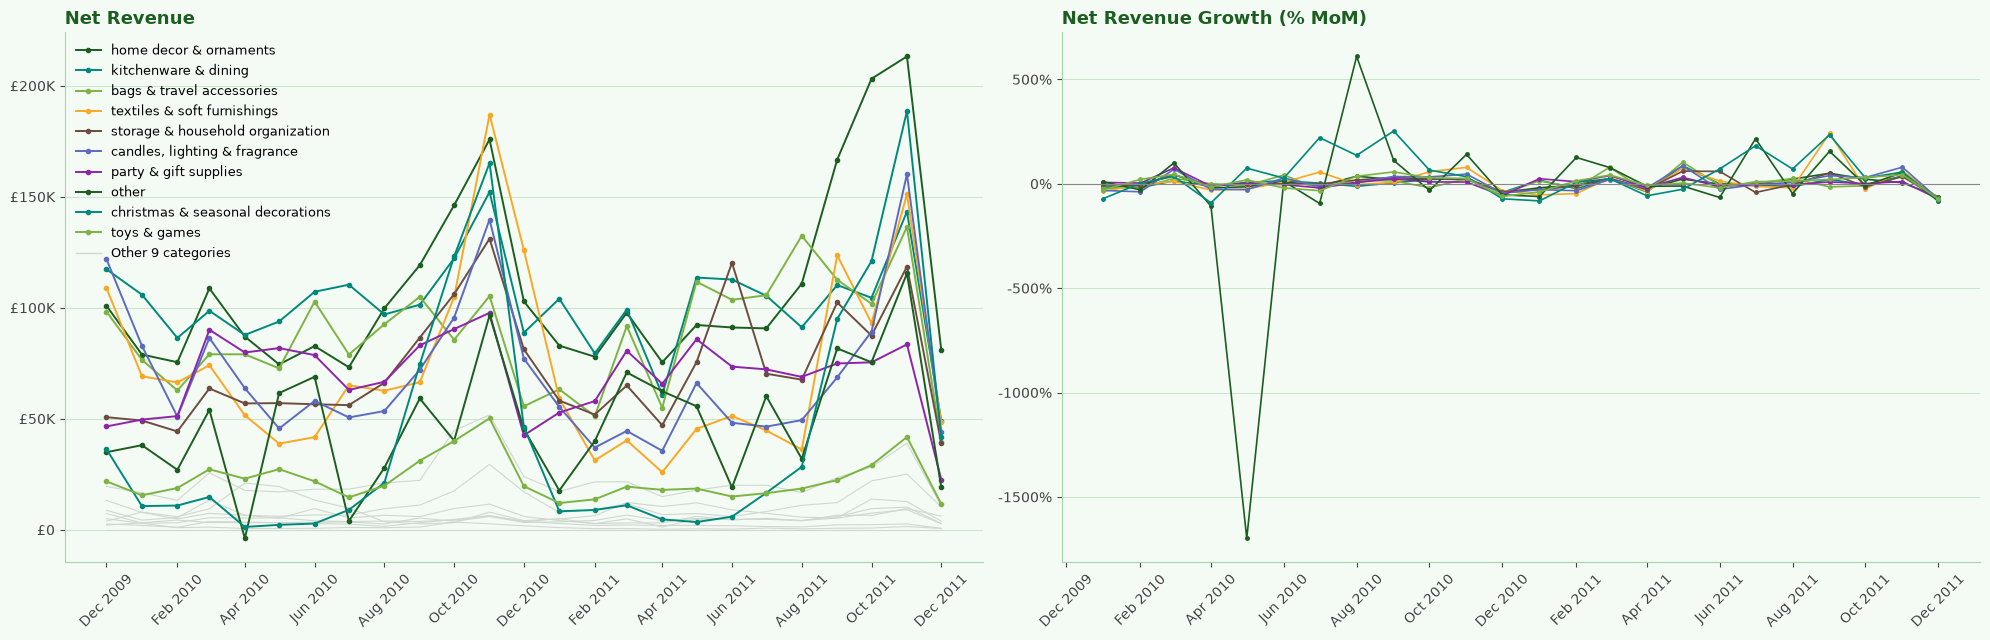

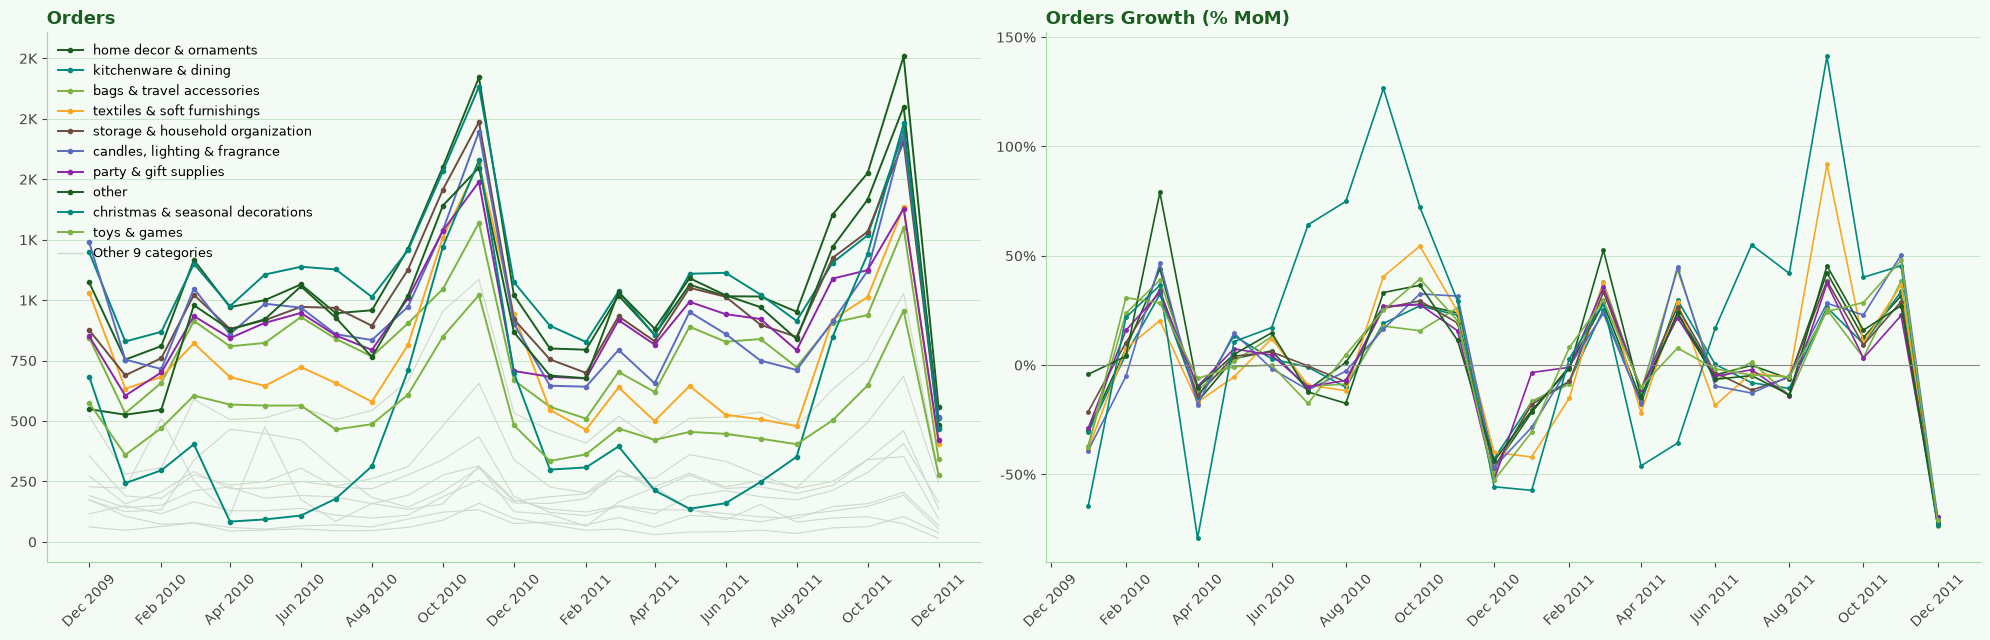

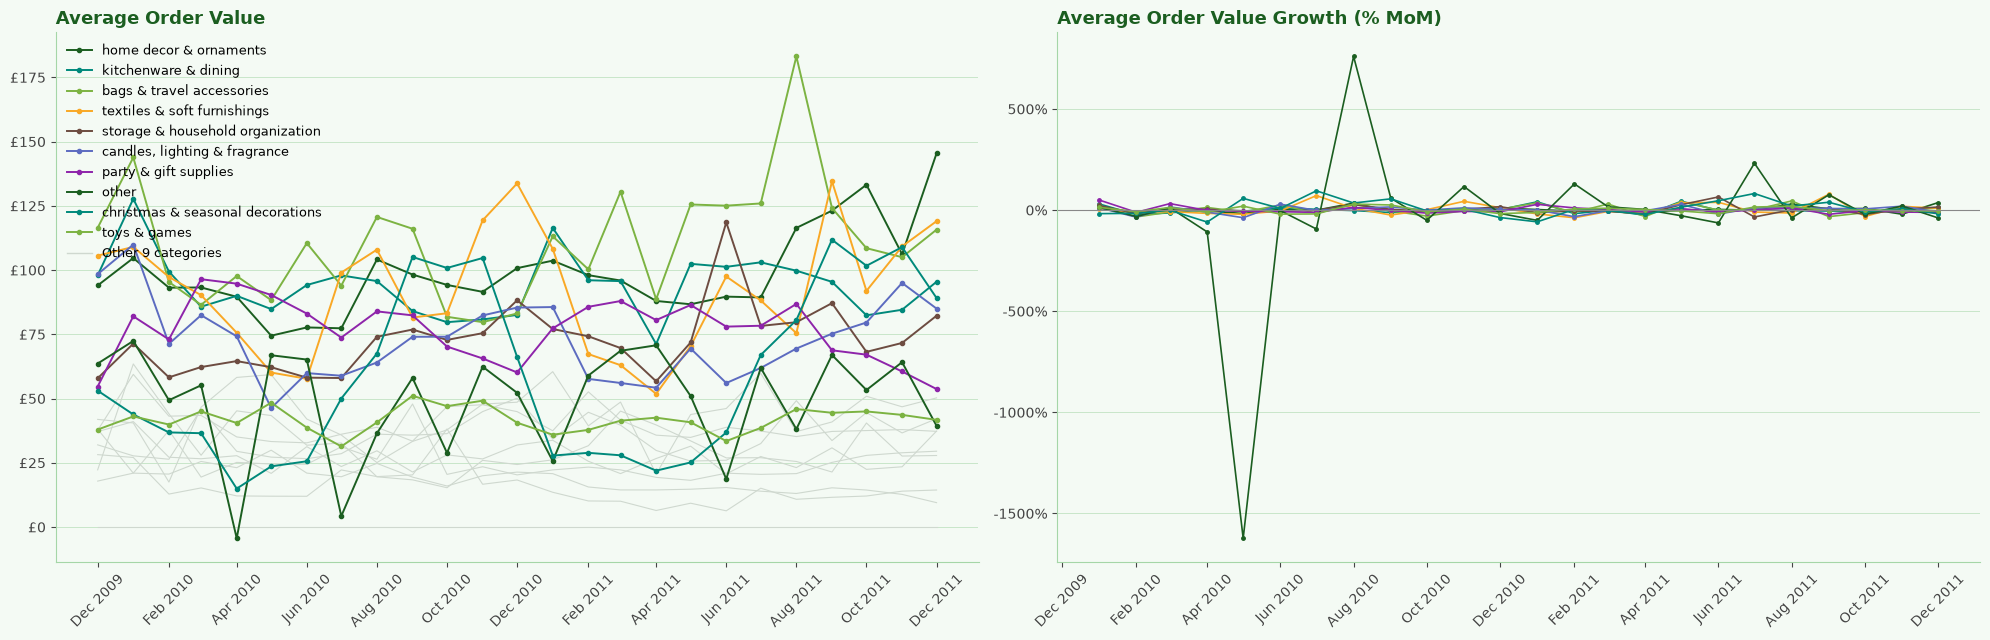

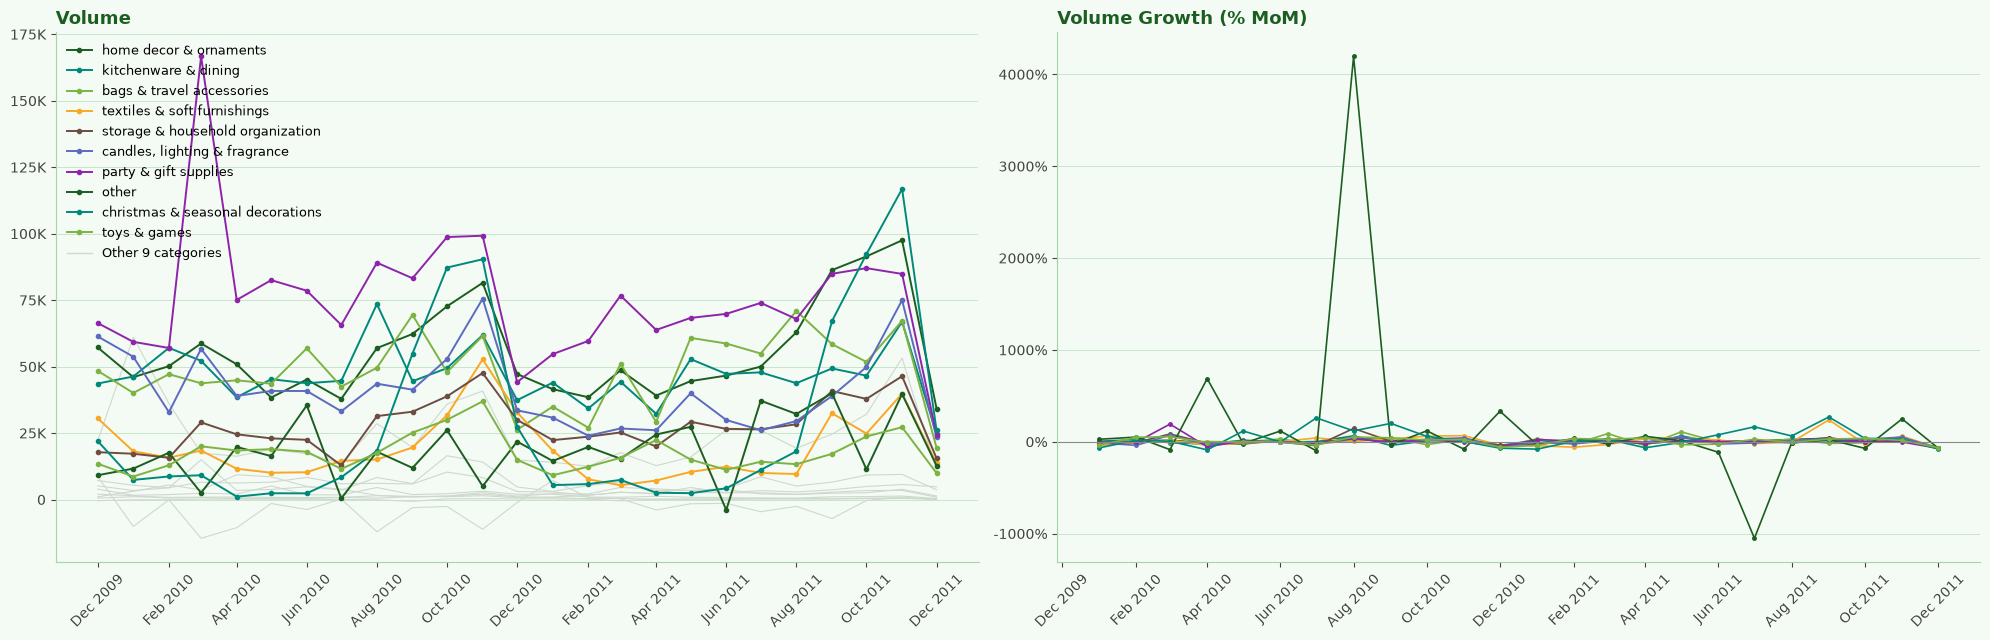

In [25]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import pandas as pd

TOP_N = 10  # change to show more or fewer highlighted categories

inventory_trends["period"] = pd.to_datetime(
    inventory_trends["year"].astype(str) + "-" + inventory_trends["month"].astype(str),
    format="%Y-%B"
)

dark, bg, grey = "#1B5E20", "#F4FAF4", "#CFD8CF"
palette = ["#1B5E20", "#00897B", "#7CB342", "#F9A825", "#6D4C41", "#5C6BC0", "#8E24AA"]

def gbp(x, _):
    if abs(x) >= 1e6: return f"£{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"£{x/1e3:.0f}K"
    return f"£{x:,.0f}"

def num(x, _):
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"{x/1e3:.0f}K"
    return f"{x:,.0f}"

pct = lambda x, _: f"{x:.0f}%"

metrics = [
    ("net_revenue", "revenue_growth_rate", "Net Revenue", gbp),
    ("orders", "orders_growth_rate", "Orders", num),
    ("aov", "aov_growth_rate", "Average Order Value", gbp),
    ("volume", "volume_growth_rate", "Volume", num),
]

cat_order = (inventory_trends.groupby("category")["net_revenue"].sum()
             .sort_values(ascending=False).index)
top = list(cat_order[:TOP_N])
rest = list(cat_order[TOP_N:])
colors = {c: palette[i % len(palette)] for i, c in enumerate(top)}

def style(a, fmt):
    a.set_facecolor(bg)
    a.yaxis.set_major_formatter(FuncFormatter(fmt))
    a.grid(axis="y", color="#C8E6C9", linewidth=0.7)
    a.set_axisbelow(True)
    for s in ["top", "right"]:
        a.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        a.spines[s].set_color("#A5D6A7")
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    a.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    a.tick_params(axis="x", rotation=45, colors="#444")
    a.tick_params(axis="y", colors="#444")

for col, gcol, title, fmt in metrics:
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(20, 6.5), facecolor=bg)

    # background: all other categories in grey (levels only)
    for cat in rest:
        d = inventory_trends[inventory_trends["category"] == cat]
        ax.plot(d["period"], d[col], color=grey, linewidth=0.8, zorder=1)

    # highlighted top categories
    for cat in top:
        d = inventory_trends[inventory_trends["category"] == cat]
        ax.plot(d["period"], d[col], color=colors[cat], linewidth=1.4,
                marker="o", markersize=3, label=cat, zorder=2)
        bx.plot(d["period"], d[gcol], color=colors[cat], linewidth=1.2,
                marker="o", markersize=2.5, zorder=2)

    ax.plot([], [], color=grey, linewidth=1, label=f"Other {len(rest)} categories")

    ax.set_title(title, fontsize=13, fontweight="bold", color=dark, loc="left")
    bx.set_title(f"{title} Growth (% MoM)", fontsize=13, fontweight="bold",
                 color=dark, loc="left")
    bx.axhline(0, color="#888", linewidth=0.8)

    style(ax, fmt)
    style(bx, pct)

    ax.legend(frameon=False, fontsize=9, loc="upper left")
    plt.tight_layout()
    plt.show()

,invoice,stockcode,description,quantity,invoicedate,price,customerid,country,year,month,day,hour,returned,gross_sales,net_sales,category
0,489434,85048,15cm christmas glass ball 20 lights,12,2009-12-01 07:45:00,6.95,13085.0,united kingdom,2009,December,Tuesday,7,no,83.40,83.40,christmas & seasonal decorations
1,489434,79323p,pink cherry lights,12,2009-12-01 07:45:00,6.75,13085.0,united kingdom,2009,December,Tuesday,7,no,81.00,81.00,"candles, lighting & fragrance"
2,489434,79323w,white cherry lights,12,2009-12-01 07:45:00,6.75,13085.0,united kingdom,2009,December,Tuesday,7,no,81.00,81.00,"candles, lighting & fragrance"
3,489434,22041,"record frame 7"" single size",48,2009-12-01 07:45:00,2.10,13085.0,united kingdom,2009,December,Tuesday,7,no,100.80,100.80,home decor & ornaments
4,489434,21232,strawberry ceramic trinket box,24,2009-12-01 07:45:00,1.25,13085.0,united kingdom,2009,December,Tuesday,7,no,30.00,30.00,storage & household organization
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1044843,581587,22899,children's apron dolly girl,6,2011-12-09 12:50:00,2.10,12680.0,france,2011,December,Friday,12,no,12.60,12.60,textiles & soft furnishings
1044844,581587,23254,childrens cutlery dolly girl,4,2011-12-09 12:50:00,4.15,12680.0,france,2011,December,Friday,12,no,16.60,16.60,kitchenware & dining
1044845,581587,23255,childrens cutlery circus parade,4,2011-12-09 12:50:00,4.15,12680.0,france,2011,December,Friday,12,no,16.60,16.60,kitchenware & dining
1044846,581587,22138,baking set 9 piece retrospot,3,2011-12-09 12:50:00,4.95,12680.0,france,2011,December,Friday,12,no,14.85,14.85,kitchenware & dining
